In [21]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.colors as mcolors
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks, butter, filtfilt
from scipy.interpolate import interp1d
from joblib import Parallel, delayed
import os, warnings
warnings.filterwarnings('ignore')

In [22]:
# ---- Physical constants ----
gamma = 1.41
R     = 287       # J/(kg·K)
cp    = 1050      # J/(kg·K)
cv    = 744       # J/(kg·K)

# ---- Pressures (Pa) ----
P_in  = 6e5
P_out = 5.45e5

# ---- Temperature (K) ----
T_in = 300.0
T0   = T_in

# ---- Resonator geometry ----
A_neck  = 2.85e-4  # m²
L_neck  = 0.15     # m
m_gas   = 0.0015   # kg
V0_cv   = 5.91e-5  # m³
V0_pass = 3.93e-4  # m³

# ---- Damping ----
b_gas = 0.01

# ---- Reed parameters ----
zeta       = 0.6
dP         = P_in - P_out
dP_max     = dP / (2 * zeta)
m_max      = 0.001
m_max_out  = 0.001 *1 
dP_max_out = dP_max

print(f"P_in  = {P_in/1e5:.3f} bar,  P_out = {P_out/1e5:.3f} bar")
print(f"dP_max = {dP_max:.1f} Pa")
print(f"m_max  = {m_max:.4f} kg/s,  m_max_out = {m_max_out:.4f} kg/s")

P_in  = 6.000 bar,  P_out = 5.450 bar
dP_max = 45833.3 Pa
m_max  = 0.0010 kg/s,  m_max_out = 0.0010 kg/s


In [23]:
def reed_flow(dP_val, m_max_val, dP_max_val):
    """Mass flow rate through a reed valve (positive = flow from high to low pressure)."""
    u = dP_val / dP_max_val
    if 0 < dP_val < dP_max_val:
        return m_max_val * (1 - u) * np.sqrt(u)
    elif dP_val <= 0:
        return -m_max_val * (1 - u) * np.sqrt(abs(u))
    else:
        return 0.0

In [24]:
# ---- Envelope analysis (same as amplitude_trajectory_analysis.ipynb) ----

def extract_envelopes(signal, peak_distance=None, smooth_cutoff_freq=None, sampling_freq=1.0):
    """
    Extract upper/lower envelopes of an oscillating signal.
    Auto-detects oscillation period from FFT if peak_distance is None.
    """
    if not isinstance(signal, np.ndarray):
        signal = np.array(signal)
    indices = np.arange(len(signal))

    if peak_distance is None:
        fft_vals = np.fft.fft(signal)
        freqs    = np.fft.fftfreq(len(signal), 1 / sampling_freq)
        pos_idx  = freqs > 0
        if np.any(pos_idx):
            idx_dom = np.argmax(np.abs(fft_vals[pos_idx]))
            dom_f   = freqs[pos_idx][idx_dom]
            peak_distance = int(sampling_freq / dom_f / 2) if dom_f > 0 else 10
        else:
            peak_distance = 10
    peak_distance = max(1, peak_distance)

    max_peaks, _ = find_peaks( signal, distance=peak_distance)
    min_peaks, _ = find_peaks(-signal, distance=peak_distance)

    if len(max_peaks) > 1:
        upper_interp = interp1d(indices[max_peaks], signal[max_peaks], kind='linear',
                                bounds_error=False,
                                fill_value=(signal[max_peaks[0]], signal[max_peaks[-1]]))
        upper = upper_interp(indices)
    else:
        upper = np.full_like(signal, np.nanmax(signal))

    if len(min_peaks) > 1:
        lower_interp = interp1d(indices[min_peaks], signal[min_peaks], kind='linear',
                                bounds_error=False,
                                fill_value=(signal[min_peaks[0]], signal[min_peaks[-1]]))
        lower = lower_interp(indices)
    else:
        lower = np.full_like(signal, np.nanmin(signal))

    upper = np.maximum(upper, lower)

    if smooth_cutoff_freq is not None:
        nyq  = 0.5 * sampling_freq
        b, a = butter(3, smooth_cutoff_freq / nyq, btype='low')
        upper = filtfilt(b, a, upper)
        lower = filtfilt(b, a, lower)

    return upper, lower


def envelope_trajectory(P_cv_arr, downsample=5, smooth_cutoff_freq=None, plot_subsample=100):
    """
    Compute amplitude and average-pressure trajectory from a P_cv time series.

    Steps
    -----
    1. Downsample by `downsample` for speed.
    2. Auto-detect oscillation peaks via FFT.
    3. Interpolate upper/lower envelopes.
    4. amplitude = (upper - lower) / 2  (always >= 0)
       average   = (upper + lower) / 2
    5. Sub-sample by `plot_subsample` for plotting.

    Returns idx, avg (Pa), amp (Pa).
    """
    P_ds   = P_cv_arr[::downsample].astype(float)
    idx_ds = np.arange(len(P_ds), dtype=float)

    upper, lower = extract_envelopes(P_ds, sampling_freq=1.0,
                                     smooth_cutoff_freq=smooth_cutoff_freq)
    avg = (upper + lower) / 2.0
    amp = np.maximum((upper - lower) / 2.0, 0.0)

    sl = slice(None, None, plot_subsample)
    return idx_ds[sl], avg[sl], amp[sl]

In [25]:
def simulate_and_trace(
    P0_val, v0_val,
    # --- physics (passed explicitly so joblib workers are stateless) ---
    _P_in, _P_out, _R, _cp, _cv, _T_in, _T0, _gamma,
    _A_neck, _V0_cv, _V0_pass, _m_gas, _b_gas,
    _m_max, _dP_max, _m_max_out, _dP_max_out,
    # --- simulation ---
    t_span=(0.0, 10.0), n_eval=100_000,
    downsample=5, plot_subsample=100,
):
    """
    Integrate the acoustic-expander ODE for initial conditions (P0_val, v0_val)
    and return the amplitude–average trajectory.

    Returns
    -------
    (P0_val, v0_val, idx, avg, amp)  — idx/avg/amp are None on failure.
    """
    # Local reed_flow so the worker is fully self-contained
    def _reed(dP_v, m_mx, dP_mx):
        u = dP_v / dP_mx
        if 0 < dP_v < dP_mx:
            return m_mx * (1 - u) * (u ** 0.5)
        elif dP_v <= 0:
            return -m_mx * (1 - u) * (abs(u) ** 0.5)
        return 0.0

    # Local envelope functions so the worker is fully self-contained
    from scipy.signal import find_peaks as _fp, butter as _bt, filtfilt as _ff
    from scipy.interpolate import interp1d as _i1d

    def _extract(sig):
        sig  = np.asarray(sig, dtype=float)
        idx  = np.arange(len(sig))
        fv   = np.fft.fft(sig)
        fr   = np.fft.fftfreq(len(sig))
        pos  = fr > 0
        pd   = int(1.0 / (fr[pos][np.argmax(np.abs(fv[pos]))] * 2)) if np.any(pos) else 10
        pd   = max(1, pd)
        mxp, _ = _fp( sig, distance=pd)
        mnp, _ = _fp(-sig, distance=pd)
        ue = _i1d(idx[mxp], sig[mxp], kind='linear', bounds_error=False,
                  fill_value=(sig[mxp[0]], sig[mxp[-1]]))(idx) if len(mxp) > 1 else np.full_like(sig, np.nanmax(sig))
        le = _i1d(idx[mnp], sig[mnp], kind='linear', bounds_error=False,
                  fill_value=(sig[mnp[0]], sig[mnp[-1]]))(idx) if len(mnp) > 1 else np.full_like(sig, np.nanmin(sig))
        return np.maximum(ue, le), le

    def _traj(pcv, ds, ps):
        pds  = pcv[::ds].astype(float)
        idxd = np.arange(len(pds), dtype=float)
        u, l = _extract(pds)
        avg  = (u + l) / 2.0
        amp  = np.maximum((u - l) / 2.0, 0.0)
        sl   = slice(None, None, ps)
        return idxd[sl], avg[sl], amp[sl]

    # ODE with P0_val captured in closure
    def ode(t, y):
        x, v, M_cv, E_cv = y
        V_cv = _V0_cv + x * _A_neck
        if V_cv <= 0 or M_cv <= 0:
            return [0.0, 0.0, 0.0, 0.0]
        T_cv = E_cv / (_cv * M_cv)
        Pcv  = M_cv * _R * T_cv / V_cv

        V_pp = _V0_pass - x * _A_neck
        P_pp = P0_val * (_V0_pass / V_pp) ** _gamma if V_pp > 0 else P0_val

        dPi = _P_in  - Pcv
        dPo = Pcv    - _P_out
        mi  = _reed(dPi, _m_max,     _dP_max)
        mo  = _reed(dPo, _m_max_out, _dP_max_out)

        dV = _A_neck * v
        return [
            v,
            (Pcv - P_pp) * _A_neck / _m_gas - (_b_gas / _m_gas) * v,
            mi - mo,
            -Pcv * dV + mi * _cp * _T_in - mo * _cp * T_cv,
        ]

    M0 = P0_val * _V0_cv / (_R * _T0)
    E0 = _cv * M0 * _T0
    y0 = [0.0, float(v0_val), M0, E0]

    try:
        sol = solve_ivp(
            ode, t_span, y0,
            t_eval=np.linspace(t_span[0], t_span[1], int(n_eval)),
            method='RK45', rtol=1e-6, atol=1e-8,
        )
        if not sol.success:
            return P0_val, v0_val, None, None, None

        x, M, E = sol.y[0], sol.y[2], sol.y[3]
        V   = _V0_cv + x * _A_neck
        T   = E / (_cv * M)
        Pcv = M * _R * T / V

        idx, avg, amp = _traj(Pcv, downsample, plot_subsample)
        return P0_val, v0_val, idx, avg, amp
    except Exception:
        return P0_val, v0_val, None, None, None

In [26]:
# ---- Scan configuration ----
P0_range = np.linspace(P_out * 0.99, P_in * 1.01, 10)   # initial pressures (Pa)
v0_range = np.linspace(-20.0, 20.0, 5)                   # initial velocities (m/s)

# Simulation settings
t_end   = 10.0      # simulation duration (s)
n_eval  = 100_000   # ODE output points  → 10 kHz effective rate
ds      = 5         # downsample stride  → 2 kHz, ~15 pts/cycle at 135 Hz
ps      = 100       # plot subsample     → ~200 trajectory points

# Physics bundle (explicit kwargs — avoids global-state issues in worker processes)
phys = dict(
    _P_in=P_in, _P_out=P_out, _R=R, _cp=cp, _cv=cv,
    _T_in=T_in, _T0=T0, _gamma=gamma,
    _A_neck=A_neck, _V0_cv=V0_cv, _V0_pass=V0_pass,
    _m_gas=m_gas, _b_gas=b_gas,
    _m_max=m_max, _dP_max=dP_max,
    _m_max_out=m_max_out, _dP_max_out=dP_max_out,
)
sim = dict(t_span=(0.0, t_end), n_eval=n_eval, downsample=ds, plot_subsample=ps)

print(f"P0 range: {P0_range.min()/1e5:.3f} – {P0_range.max()/1e5:.3f} bar  ({len(P0_range)} values)")
print(f"v0 range: {v0_range.min():.1f}  – {v0_range.max():.1f} m/s   ({len(v0_range)} values)")
print(f"Total runs: {len(P0_range) * len(v0_range)}")

P0 range: 5.396 – 6.060 bar  (10 values)
v0 range: -20.0  – 20.0 m/s   (5 values)
Total runs: 50


In [27]:
# ---- Parallel scan ----
for _k in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS",
           "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(_k, "1")

tasks = [(P0, v0) for P0 in P0_range for v0 in v0_range]
print(f"Launching {len(tasks)} simulations ...")

results = Parallel(n_jobs=-1, verbose=5, backend="loky")(
    delayed(simulate_and_trace)(P0, v0, **phys, **sim)
    for P0, v0 in tasks
)

good = sum(1 for r in results if r[2] is not None)
print(f"\nDone: {good}/{len(results)} successful runs")

Launching 50 simulations ...


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  38 out of  50 | elapsed:   20.3s remaining:    6.4s



Done: 50/50 successful runs


[Parallel(n_jobs=-1)]: Done  50 out of  50 | elapsed:   25.2s finished


Saved → /Users/a1/Desktop/acoustic project/acoustic_expander/trajectory_scan_amplitude_vs_avg.pdf


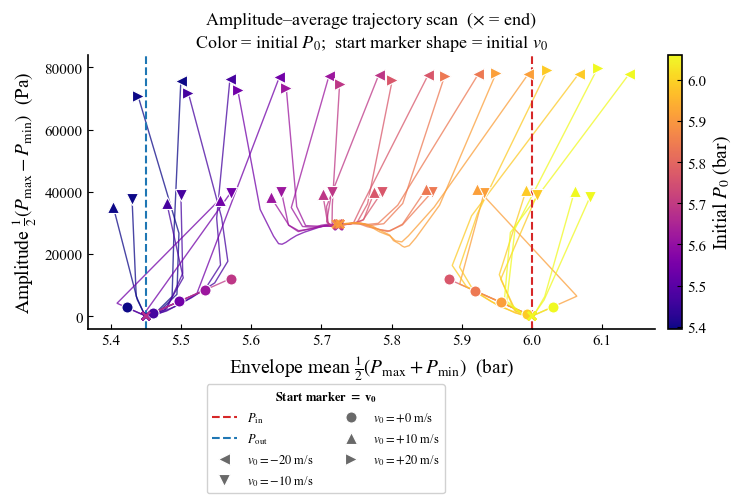

In [29]:
# ---- Plot: amplitude vs average pressure ----
# Color  = P0  (plasma colormap + right colorbar)
# Marker = v0  (directional shapes + legend)
# End of each trajectory marked with  ×

from matplotlib.lines import Line2D

# Directional markers: <  v  o  ^  >  (hint at sign/magnitude of velocity)
# Matches v0_range = [-20, -10, 0, +10, +20]
MARKERS   = ['<', 'v', 'o', '^', '>']
v0_sorted = np.sort(v0_range)

def v0_marker(v0_val):
    """Return marker shape for the closest v0 in v0_sorted."""
    idx = int(np.argmin(np.abs(v0_sorted - v0_val)))
    return MARKERS[idx]

with mpl.rc_context({
    "font.family":    "serif",
    "font.serif":     ["Times New Roman", "Times", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size":      13,
    "axes.labelsize": 14,
    "axes.titlesize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.linewidth": 1.2,
    "xtick.direction": "in",
    "ytick.direction": "in",
}):
    fig, ax = plt.subplots(figsize=(8, 5.5))

    # ---- P0 colormap ----
    cmap = plt.get_cmap("plasma")
    norm = mcolors.Normalize(vmin=P0_range.min() / 1e5, vmax=P0_range.max() / 1e5)
    sm   = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])

    for (P0_val, v0_val, idx, avg, amp) in results:
        if idx is None:
            continue
        color  = cmap(norm(P0_val / 1e5))
        marker = v0_marker(v0_val)
        ax.plot(avg / 1e5, amp, color=color, lw=1.0, alpha=0.75)
        # Start: distinctive marker shape (filled, larger)
        ax.plot(avg[0]  / 1e5, amp[0],  marker, color=color,
                ms=8, zorder=6, markeredgewidth=0.8, markeredgecolor='white')
        # End: uniform × for all
        ax.plot(avg[-1] / 1e5, amp[-1], 'x', color=color,
                ms=6, zorder=6, mew=1.5, alpha=0.85)

    # ---- Right colorbar: P0 ----
    cbar = fig.colorbar(sm, ax=ax, pad=0.02)
    cbar.set_label(r"Initial $P_0$ (bar)")
    cbar.outline.set_linewidth(1.2)

    # ---- Reference lines (drawn, but added to legend manually) ----
    ax.axvline(P_in  / 1e5, ls="--", lw=1.5, color="tab:red")
    ax.axvline(P_out / 1e5, ls="--", lw=1.5, color="tab:blue")

    # ---- Combined legend: reference lines + v0 markers ----
    h_in  = Line2D([0],[0], ls='--', lw=1.5, color='tab:red',
                   label=r"$P_{\mathrm{in}}$")
    h_out = Line2D([0],[0], ls='--', lw=1.5, color='tab:blue',
                   label=r"$P_{\mathrm{out}}$")
    mk_handles = [
        Line2D([0],[0], marker=m, color='dimgray', lw=0,
               ms=8, markeredgewidth=0.8, markeredgecolor='white',
               markerfacecolor='dimgray',
               label=f"$v_0 = {v:+.0f}$ m/s")
        for v, m in zip(v0_sorted, MARKERS)
    ]
    ax.legend(
        handles=[h_in, h_out] + mk_handles,
        title=r"$\bf{Start\ marker}\ =\ v_0$",
        title_fontsize=9, fontsize=9,
        framealpha=0.9, ncol=2,
        loc='upper center',
        bbox_to_anchor=(0.42, -0.18),
    )

    ax.set_xlabel(r"Envelope mean $\frac{1}{2}(P_{\max}+P_{\min})$  (bar)")
    ax.set_ylabel(r"Amplitude $\frac{1}{2}(P_{\max}-P_{\min})$  (Pa)")
    ax.set_title(
        r"Amplitude–average trajectory scan  ($\times$ = end)"
        "\nColor = initial $P_0$;  start marker shape = initial $v_0$"
    )
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()

    base      = os.path.dirname(os.path.abspath("__file__"))
    save_path = os.path.join(base, "trajectory_scan_amplitude_vs_avg.pdf")
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    print(f"Saved → {save_path}")
    plt.show()